# 04_Company_Masking — Brand Shortcuts & [COMPANY] Variant

In [1]:
import os
if 'notebooks' in os.getcwd():
    os.chdir('..')
os.makedirs('output', exist_ok=True)
print(f'Working directory: {os.getcwd()}')

Working directory: D:\Data analyst\Portfolio\Banque\bank-complaint-routing-nlp


In [2]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.width', 200)
print('✓ Libraries loaded')

✓ Libraries loaded


In [3]:
lex = pd.read_csv('reports/phase3a/lexicon_patterns.csv', keep_default_na=False)
cand = pd.read_csv('reports/phase3a/single_token_candidates.csv')
cov = pd.read_csv('reports/phase3a/coverage_by_split_service.csv')
ba = pd.read_csv('reports/phase3a/top15_words_before_after.csv')
print(f"Lexicon patterns: {len(lex):,} (single tokens selected: {int(cand['selected'].sum())} of {len(cand)})")

Lexicon patterns: 490 (single tokens selected: 166 of 405)


## 1. Coverage by Split and Service

% of narratives with at least one [COMPANY]:
                 service  train   val  test
        Comptes & Dépôts  65.52 65.62 64.90
       Crédit immobilier  52.28 52.10 54.29
Crédits aux particuliers  49.60 48.93 49.30
               Monétique  60.27 61.23 59.03
            Recouvrement  28.77 29.56 29.80
  Transferts & Paiements  49.80 49.80 48.22


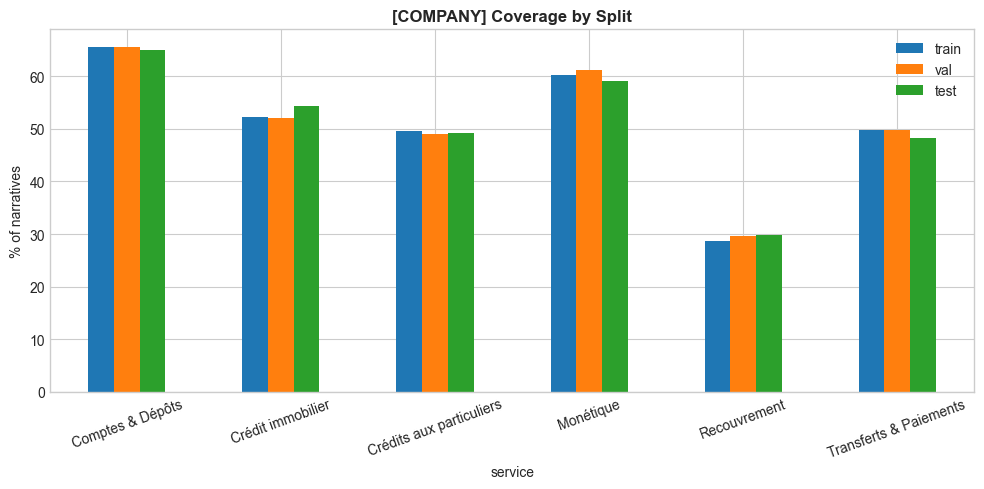

✓ Saved: 04_company_mask_coverage.png


In [4]:
print('% of narratives with at least one [COMPANY]:'); print(cov.to_string(index=False))
ax = cov.set_index('service')[['train', 'val', 'test']].plot.bar(figsize=(10, 5), rot=20)
ax.set_title('[COMPANY] Coverage by Split', fontsize=12, fontweight='bold'); ax.set_ylabel('% of narratives')
plt.tight_layout()
plt.savefig('output/04_company_mask_coverage.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 04_company_mask_coverage.png')

## 2. Most Frequent Matches

In [5]:
print(pd.read_csv('reports/phase3a/top_matches.csv').head(20).to_string(index=False))

    matched_text  n_occurrences
           chase          18480
     wells fargo          17540
     capital one          13972
          paypal          13851
 bank of america          11948
           chime           9117
        citibank           8541
       synchrony           6537
american express           5490
          mohela           4555
          affirm           3656
          truist           3304
            sofi           3032
            navy           2716
        barclays           2560
            ally           2490
 rocket mortgage           2275
       santander           2053
         td bank           1982
      shellpoint           1946


## 3. Discriminant Words Before / After Masking (train)

      word  train_count_before  train_count_after  pct_removed
    affirm                2603                  0        100.0
  barclays                1894                  0        100.0
     chime                6313                  0        100.0
   express                4295                  0        100.0
     fargo               12369                  0        100.0
  coinbase                1195                  0        100.0
    nelnet                1203                  0        100.0
   paypals                 706                  0        100.0
    paypal                9637                  0        100.0
    rocket                1976                  0        100.0
    mohela                3214                  0        100.0
 synchrony                4632                  0        100.0
shellpoint                1305                  0        100.0
     wells               13110                  0        100.0
  american                4510                409      

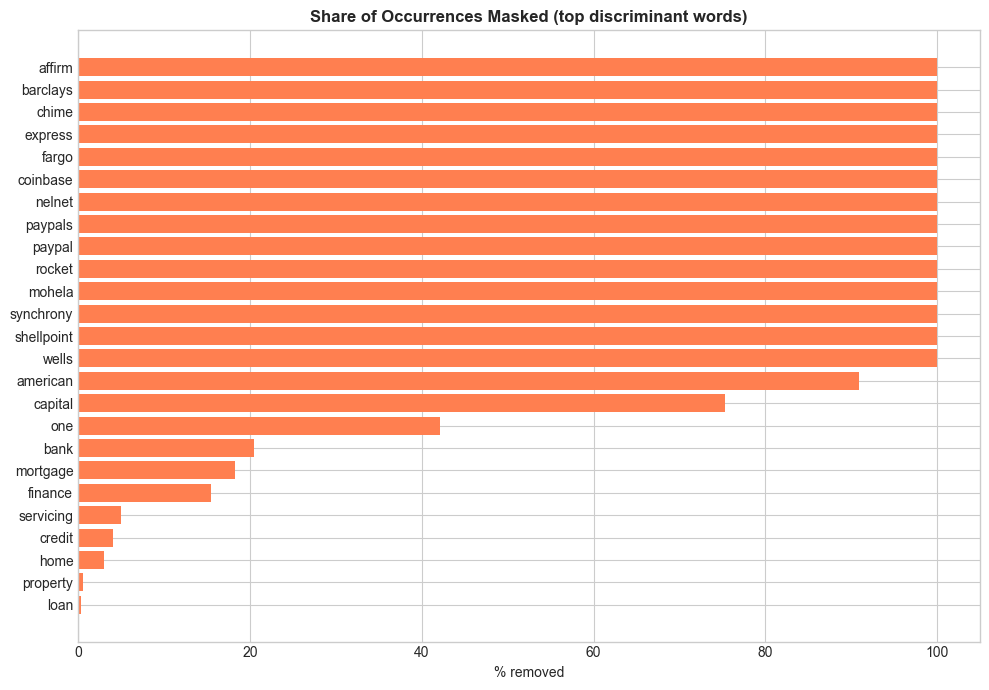

✓ Saved: 04_brand_words_removed.png


In [6]:
d = ba.dropna(subset=['pct_removed']).sort_values('pct_removed', ascending=False).head(25)
print(d.to_string(index=False))
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(d['word'][::-1], d['pct_removed'][::-1], color='coral')
ax.set_title('Share of Occurrences Masked (top discriminant words)', fontsize=12, fontweight='bold')
ax.set_xlabel('% removed')
plt.tight_layout()
plt.savefig('output/04_brand_words_removed.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 04_brand_words_removed.png')

## 4. Residual Brands & False-Positive Bound

In [7]:
print('Discriminant words NOT captured (pct_removed = 0):')
print(', '.join(ba.loc[ba['pct_removed'] == 0, 'word'].tolist()))
s = cand[cand['selected'] & (cand['concentration'] < 0.8)].copy()
s['max_false_positive_docs'] = (s['n_docs'] * (1 - s['concentration'])).round().astype(int)
print('\nSelected single tokens with concentration < 0.8 (upper bound of false positives):')
print(s.sort_values('max_false_positive_docs', ascending=False).head(15)[
    ['token', 'n_docs', 'concentration', 'n_company_names', 'max_false_positive_docs']].to_string(index=False))

Discriminant words NOT captured (pct_removed = 0):
auto, billing, app, atm, act, alleged, cash, card, checking, check, charges, charge, cashapp, cease, deposited, escrow, fcra, fair, creditor, deposit, debit, dealership, collect, citi, money, modification, mitigation, merchant, interest, loans, funds, insurance, fdcpa, fha, forgiveness, foreclosure, overdraft, original, repayment, recipient, rewards, repossession, reporting, report, scam, student, support, servicer, taxes, transaction, transfer, transactions, validation, vehicle, venmo, wire

Selected single tokens with concentration < 0.8 (upper bound of false positives):
      token  n_docs  concentration  n_company_names  max_false_positive_docs
    express    1332          0.725                1                      366
     global     327          0.716                2                       93
      fifth     258          0.671                1                       85
    freedom     340          0.756                2          